# RainView: первый график

За один вызов сравним оценки трёх учебных групп. Все данные искусственные. В CSV намеренно оставлены два пропуска оценки и одна пропущенная метка группы, чтобы показать очистку и сводку. Для установки пакета см. README.

In [1]:
import sys
from pathlib import Path

# Примеры работают из корня проекта и из папки examples.
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Откройте ноутбук из папки проекта RainView.")
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from rainview import format_summary, raincloudplot, save_plot

%matplotlib inline

In [2]:
data = pd.read_csv(ROOT / "data" / "education.csv")
data.head()

,method,score
0,Традиционный,58.9
1,Традиционный,68.2
2,Традиционный,48.9
3,Традиционный,78.6
4,Традиционный,71.7


## Один вызов и три слоя

Слева от каждого ящика — half-violin, в центре — медиана, квартили и усы, справа — реальные наблюдения со случайным смещением только вдоль категориальной оси. Фиксированный random_state делает смещение повторяемым.

/tmp/ipykernel_24884/591020620.py:1: MissingDataWarning: Исключено строк с пропусками: 3 из 150. Подробности находятся в summary.
  fig, ax, summary = raincloudplot(


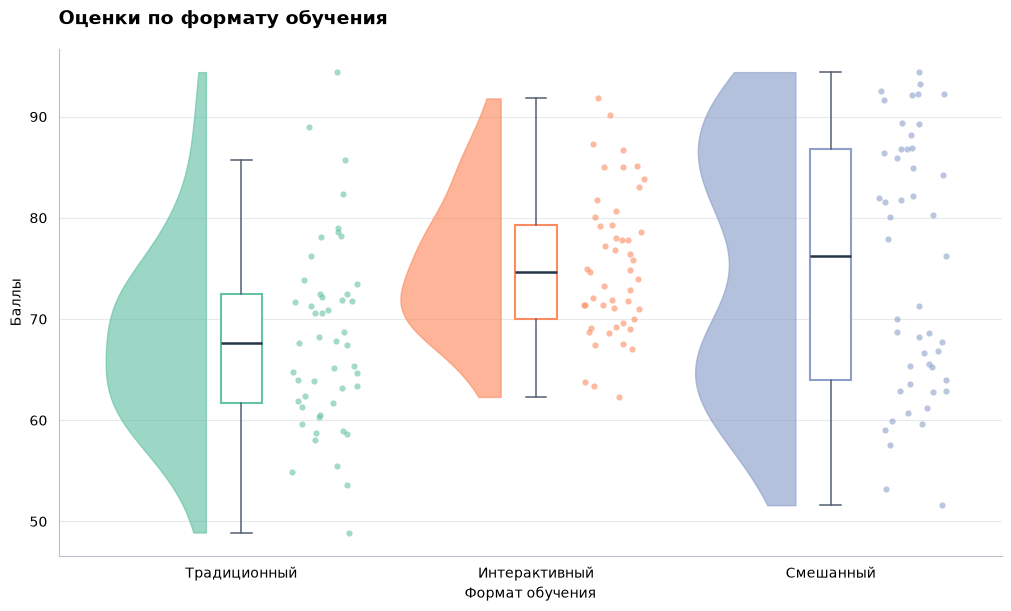

In [3]:
fig, ax, summary = raincloudplot(
    data,
    value="score",
    group="method",
    title="Оценки по формату обучения",
    x_label="Формат обучения",
    y_label="Баллы",
    random_state=42,
)
plt.show()

In [4]:
print(format_summary(summary))

Всего строк: 150; использовано: 147; исключено: 3.
Из них без метки группы: 1.
Традиционный: n=49, среднее=68.04, медиана=67.6, std=9.214, min=48.9, max=94.4, исключено в группе=1.
Интерактивный: n=49, среднее=75.3, медиана=74.6, std=7.034, min=62.3, max=91.8, исключено в группе=1.
Смешанный: n=49, среднее=75.15, медиана=76.2, std=12.61, min=51.6, max=94.4, исключено в группе=0.


## Проверка состава данных

Строка без метки группы учтена отдельно. Пропуски оценки в известных группах учтены внутри summary["groups"]. Каждая исключённая строка входит в общий счётчик ровно один раз.

In [5]:
assert summary["total_rows"] == 150
assert summary["valid_rows"] == 147
assert summary["dropped_rows"] == 3
assert summary["missing_group_rows"] == 1
pd.DataFrame.from_dict(summary["groups"], orient="index")

,n,mean,median,min,max,std,q1,q3,dropped_rows
Традиционный,49,68.042857,67.6,48.9,94.4,9.214233,61.7,72.5,1
Интерактивный,49,75.297959,74.6,62.3,91.8,7.034394,70.0,79.3,1
Смешанный,49,75.146939,76.2,51.6,94.4,12.610910,64.0,86.8,0


## PNG и SVG

Запись выполняется только при явном вызове save_plot или fig.savefig.

In [6]:
output = ROOT / "outputs" / "notebooks"
output.mkdir(parents=True, exist_ok=True)
save_plot(fig, output / "quickstart.png")
save_plot(fig, output / "quickstart.svg")
print("Сохранено:", output.relative_to(ROOT))

Сохранено: outputs/notebooks


График и сводка описывают наблюдения. Они не являются проверкой статистической значимости и не показывают причинный эффект формата обучения.